
#  RFM Feature Engineering

## Objective

Build a customer-level dataset containing the three RFM (Recency, Frequency, Monetary) features.

RFM analysis helps understand customer purchasing behaviour through three dimensions:

- **Recency (R):** How recently a customer made a purchase.
- **Frequency (F):** How often a customer made a purchase.
- **Monetary (M):** How much a customer spent.

The analysis uses delivered orders only. The features will be calculated and examined individually before combining them into a single customer-level RFM dataset.

The resulting dataset will be used in the next milestone for customer scoring and segmentation.


In [91]:
import sys
from pathlib import Path

# Add project root to Python's import path
project_root = Path.cwd().parent
sys.path.insert(0, str(project_root))

import pandas as pd
from sqlalchemy import text

from src.db import engine, test_connection

test_connection()

('neondb', 'ecom', 'PostgreSQL 18.7 (84da7d8) on aarch64-unknown-linux-gnu, compiled by gcc (Ubuntu 13.3.0-6ubuntu2~24.04.1) 13.3.0, 64-bit')

In [92]:
query="""
select count(*) from ecom.orders
""" 

orders_check_df = pd.read_sql(text(query), engine)
orders_check_df

,count
0,40000


## 1. Define the RFM Reference Date

### Snapshot Date

The analysis snapshot date is **June 15, 2026**.

The latest delivered order in the dataset was recorded on June 14, 2026. Therefore, June 15 is used as the reference date for calculating customer Recency.

Using a fixed snapshot date ensures that Recency calculations are consistent and reproducible.

### Order Eligibility

Only orders with a normalized status of `delivered` are included in the RFM calculations. This excludes cancelled and other non-delivered orders.


In [93]:
snapshot_date = pd.Timestamp("2026-06-15").date()

print("RFM Snapshot Date:", snapshot_date)

RFM Snapshot Date: 2026-06-15



## 2. Recency

### Definition

Recency measures the number of days since a customer's most recent delivered purchase.


Recency = Snapshot Date - Last Purchase Date


A lower Recency value indicates a more recent purchase, while a higher value indicates that more time has passed since the customer's last purchase.

### Calculation

For each customer, identify the latest delivered order date. Calculate the difference between this date and the analysis snapshot date of June 15, 2026.

Only customers with at least one delivered order are included in the initial Recency dataset.


In [94]:
query = """
SELECT
    customer_id,
    MAX(created_at)::date AS last_purchase_date
FROM ecom.orders
WHERE LOWER(TRIM(status)) = 'delivered'
GROUP BY customer_id
ORDER BY customer_id;
"""

recency_df = pd.read_sql(text(query), engine)

print(recency_df.head())
print(recency_df.shape)

   customer_id last_purchase_date
0            1         2026-05-25
1            2         2026-05-07
2            4         2026-05-27
3            7         2026-05-09
4            9         2026-04-26
(6052, 2)



### 2.1 Recency Distribution

Examine the distribution of customer Recency using descriptive statistics and a histogram.

The analysis focuses on the median, spread, range and shape of the distribution. These help identify how recently customers have purchased and whether the customer base contains groups with substantially different purchase recency.

A lower Recency value is generally preferable from a customer-engagement perspective.


In [95]:
# Convert last_purchase_date to Pandas datetime
recency_df['last_purchase_date'] = pd.to_datetime(
    recency_df['last_purchase_date']
)

# Calculate Recency in days
recency_df['recency'] = (
    pd.Timestamp(snapshot_date) - recency_df['last_purchase_date']
).dt.days

recency_df.head(10)

,customer_id,last_purchase_date,recency
0,1,2026-05-25,21
1,2,2026-05-07,39
2,4,2026-05-27,19
3,7,2026-05-09,37
4,9,2026-04-26,50
5,10,2026-04-27,49
6,13,2026-04-28,48
7,14,2026-05-20,26
8,16,2026-05-15,31
9,18,2026-05-07,39


In [96]:
recency_df['recency'].describe()

count    6052.000000
mean       41.057336
std        25.480830
min         1.000000
25%        19.000000
50%        39.000000
75%        64.000000
max        91.000000
Name: recency, dtype: float64

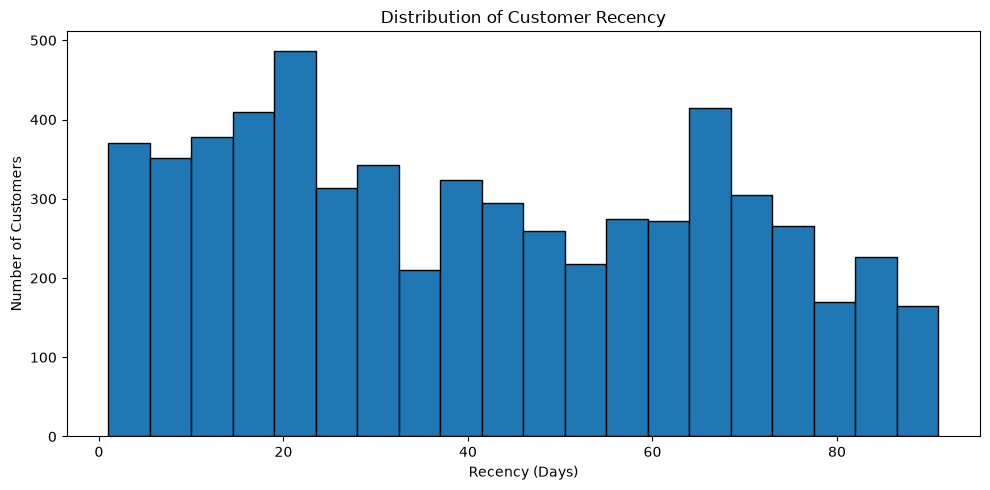

In [97]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(
    recency_df['recency'],
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Customer Recency')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


## 3. Frequency

### Definition

Frequency measures the number of delivered orders placed by each customer during the available dataset period.

Frequency = Count of Delivered Orders

Each delivered order is counted once. Cancelled and non-delivered orders are excluded.

A higher Frequency indicates that a customer has purchased more often during the observation period.


In [98]:
query = """
SELECT
    customer_id,
    COUNT(*) AS frequency
FROM ecom.orders
WHERE LOWER(TRIM(status)) = 'delivered'
GROUP BY customer_id;
"""

frequency_df = pd.read_sql(text(query), engine)

frequency_df.head()

,customer_id,frequency
0,1,4
1,2,1
2,4,3
3,7,1
4,9,2



### 3.1 Frequency Distribution

Examine the distribution of customer order frequency using descriptive statistics and histograms.

Pay particular attention to:

- The proportion of customers who placed only one order.
- The median number of orders.
- The spread between low- and high-frequency customers.
- The presence of a long right tail.

A zoomed histogram is also used to examine the distribution among customers with relatively fewer orders, while retaining the full distribution for context.


In [99]:
frequency_df['frequency'].describe()

count    6052.000000
mean        3.301223
std         5.768117
min         1.000000
25%         1.000000
50%         1.000000
75%         4.000000
max       102.000000
Name: frequency, dtype: float64

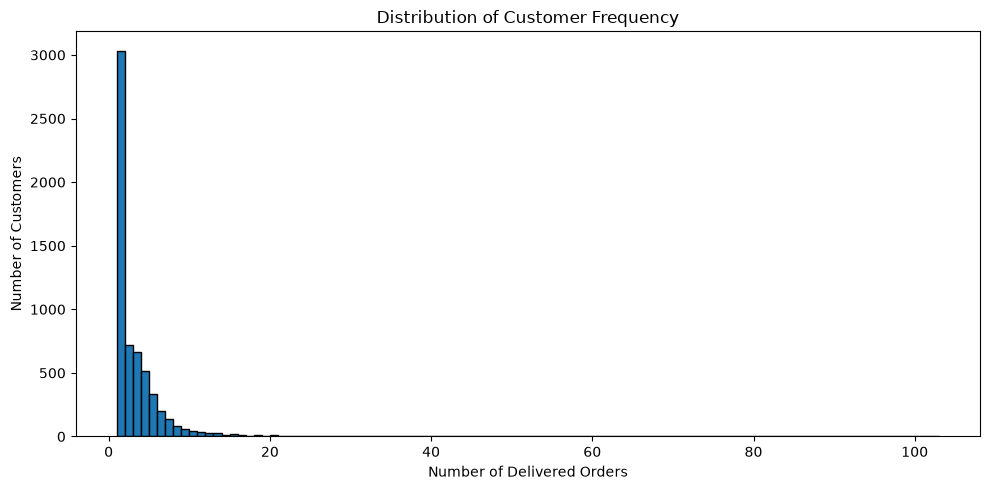

In [100]:
plt.figure(figsize=(10, 5))

plt.hist(
    frequency_df['frequency'],
    bins=range(1, frequency_df['frequency'].max() + 2),
    edgecolor='black'
)

plt.title('Distribution of Customer Frequency')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers')

plt.tight_layout()
plt.show()


Zooming in the histogram


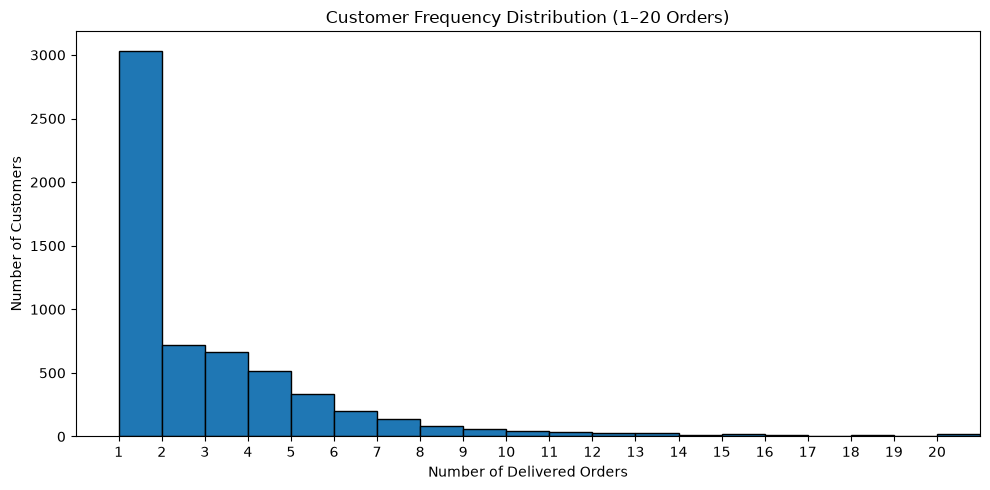

In [101]:
plt.figure(figsize=(10, 5))

plt.hist(
    frequency_df['frequency'],
    bins=range(1, 22),
    edgecolor='black'
)

plt.title('Customer Frequency Distribution (1–20 Orders)')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers')

plt.xticks(range(1, 21))
plt.xlim(0, 21)

plt.tight_layout()
plt.show()


### 3.2 Investigating High-Frequency Customers

The Frequency distribution contains a small number of customers with unusually high order counts.

Rather than automatically treating these observations as errors or removing them, investigate the highest-frequency customers.

The investigation examines order IDs, purchase dates, daily order counts and payment information to assess whether the high frequency could represent genuine purchasing behaviour or a data-quality issue.

Unusual observations should only be excluded when there is sufficient evidence that they are invalid.


In [102]:
frequency_df.sort_values(
    by='frequency',
    ascending=False
).head(10)

,customer_id,frequency
225,371,102
4646,7667,95
3880,6434,91
1552,2570,90
3691,6117,80
2299,3825,77
1541,2553,74
4879,8052,73
382,642,70
104,187,69


In [103]:
query = """
SELECT
    customer_id,
    COUNT(*) AS delivered_orders,
    MIN(created_at) AS first_delivered_order,
    MAX(created_at) AS last_delivered_order,
    COUNT(DISTINCT created_at::date) AS active_purchase_days
FROM ecom.orders
WHERE customer_id = 371
  AND LOWER(TRIM(status)) = 'delivered'
GROUP BY customer_id;
"""

customer_check = pd.read_sql(text(query), engine)
customer_check

,customer_id,delivered_orders,first_delivered_order,last_delivered_order,active_purchase_days
0,371,102,2026-03-18 13:05:57+00:00,2026-06-12 09:50:59+00:00,48


In [104]:
query = """
SELECT
    created_at::date AS order_date,
    COUNT(*) AS orders_on_day
FROM ecom.orders
WHERE customer_id = 371
  AND LOWER(TRIM(status)) = 'delivered'
GROUP BY created_at::date
ORDER BY orders_on_day DESC, order_date;
"""

daily_orders_371 = pd.read_sql(text(query), engine)

daily_orders_371.head(15)

,order_date,orders_on_day
0,2026-03-18,6
1,2026-03-25,6
2,2026-04-02,5
3,2026-03-31,4
4,2026-04-09,4
5,2026-04-16,4
6,2026-05-09,4
7,2026-05-20,4
8,2026-03-19,3
9,2026-03-22,3


In [105]:
query = """
SELECT
    order_id,
    created_at,
    total,
    payment_status
FROM ecom.orders
WHERE customer_id = 371
  AND LOWER(TRIM(status)) = 'delivered'
ORDER BY created_at
LIMIT 15;
"""

customer_orders_371 = pd.read_sql(text(query), engine)

customer_orders_371

,order_id,created_at,total,payment_status
0,1125,2026-03-18 13:05:57+00:00,9376.28,paid
1,1015,2026-03-18 16:18:16+00:00,2417.82,paid
2,1062,2026-03-18 17:03:53+00:00,942.82,paid
3,38423,2026-03-18 17:43:39+00:00,293.82,paid
4,26044,2026-03-18 17:57:18+00:00,942.82,paid
5,10797,2026-03-18 20:35:30+00:00,2594.82,paid
6,22328,2026-03-19 10:12:58+00:00,2238.46,paid
7,1514,2026-03-19 13:15:04+00:00,234.82,paid
8,25623,2026-03-19 16:01:40+00:00,31261.74,paid
9,1837,2026-03-20 17:57:48+00:00,3418.46,paid



## 4. Gross Monetary

### Definition

Monetary measures the total value of delivered orders associated with each customer.

For the initial calculation, gross Monetary is defined as:


Gross Monetary = sum (Delivered Order Total)


The calculation uses `orders.total`, which includes the order subtotal, tax and shipping charges.

This provides the gross delivered order value before accounting for successful refunds.

### Why examine gross Monetary first?

Gross Monetary provides a baseline for customer spending. Successful refunds will be deducted separately to derive the final net Monetary feature.


In [106]:
query = """
SELECT
    customer_id,
    SUM(total) AS monetary
FROM ecom.orders
WHERE LOWER(TRIM(status)) = 'delivered'
GROUP BY customer_id;
"""

monetary_df = pd.read_sql(text(query), engine)
print(monetary_df.head())


   customer_id  monetary
0            1  78694.94
1            2   3181.28
2            4  26601.92
3            7   1010.82
4            9   4302.28



### 4.1 Gross Monetary Distribution

Examine customer spending using descriptive statistics and histograms.

The analysis considers the mean, median, quartiles, standard deviation and range to understand the spread of customer spending.

The linear-scale histogram shows the overall distribution, while the logarithmic-scale histogram provides a supplementary view of spending across a wider range of values.

Particular attention is given to right skewness and the presence of high-spending customers, since these observations can influence the mean and the overall distribution.


In [107]:
monetary_df['monetary'].describe()

count      6052.000000
mean      24854.302323
std       47119.332451
min         175.820000
25%        4245.345000
50%       11441.870000
75%       28363.070000
max      795745.260000
Name: monetary, dtype: float64

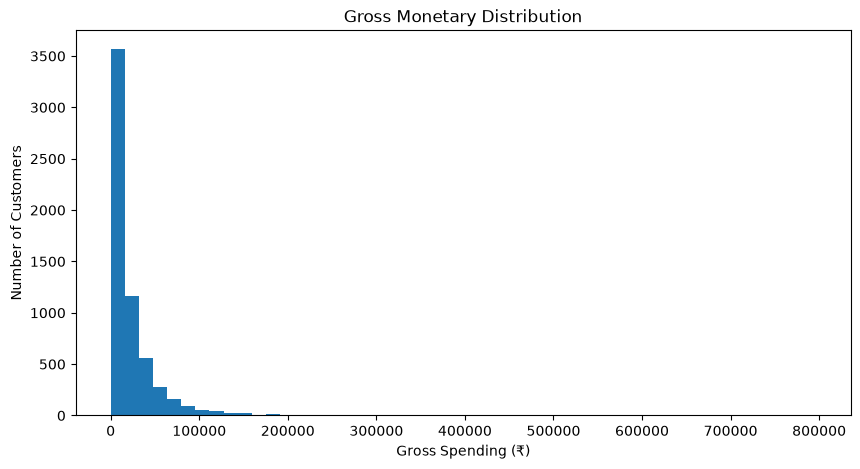

In [108]:
plt.figure(figsize=(10, 5))

plt.hist(monetary_df['monetary'], bins=50)

plt.title('Gross Monetary Distribution')
plt.xlabel('Gross Spending (₹)')
plt.ylabel('Number of Customers')

plt.show()

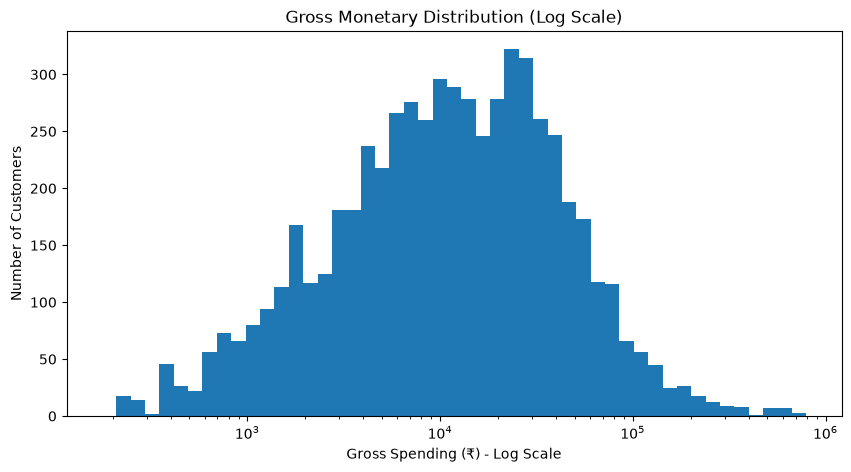

In [109]:
import numpy as np

monetary = monetary_df['monetary']

log_bins = np.logspace(
    np.log10(monetary.min()),
    np.log10(monetary.max()),
    50
)

plt.figure(figsize=(10, 5))

plt.hist(monetary, bins=log_bins)
plt.xscale('log')

plt.title('Gross Monetary Distribution (Log Scale)')
plt.xlabel('Gross Spending (₹) - Log Scale')
plt.ylabel('Number of Customers')

plt.show()


## 5. Refund Adjustments

### Objective
Calculate successful refunds at the customer level so that Monetary reflects net spending rather than gross delivered order value.

### Business Rule
Only refunds with a `succeeded` status are deducted from customer spending.

- **Succeeded:** Deduct from customer spending.
- **Initiated:** Do not deduct; the refund is not yet completed.
- **Failed:** Do not deduct; the refund was unsuccessful.

### Approach
Load the refund records into Pandas, filter successful refunds, and aggregate refund amounts before calculating net Monetary.

This ensures that each customer's refund amount is accounted for without duplicating order records.


In [110]:
query = """
SELECT
    order_id,
    amount,
    status
FROM ecom.refunds;
"""

refunds_df = pd.read_sql(text(query), engine)

refunds_df.head()

,order_id,amount,status
0,21066,7251.23,succeeded
1,28132,9848.28,succeeded
2,11815,4244.46,succeeded
3,23663,938.58,succeeded
4,8528,11394.44,succeeded



### 5.1 Filter Successful Refunds

Only completed refunds should reduce customer spending.

Filter the refund dataset to retain records where the refund status is `succeeded`. Initiated and failed refunds are excluded because the money has not been successfully returned to the customer.


In [111]:
successful_refunds = refunds_df[
    refunds_df['status'].str.strip().str.lower() == 'succeeded'
].copy()

print(successful_refunds.head())
successful_refunds.shape

   order_id    amount     status
0     21066   7251.23  succeeded
1     28132   9848.28  succeeded
2     11815   4244.46  succeeded
3     23663    938.58  succeeded
4      8528  11394.44  succeeded


(227, 3)


### 5.2 Aggregate Successful Refunds by Order

An order may have more than one refund record. Before calculating customer-level refunds, aggregate all successful refund amounts by `order_id`.

This produces one row per refunded order and prevents duplicate order records when refund data is later joined with order data.


In [112]:
refunds_by_order = (
    successful_refunds
    .groupby('order_id')
    .agg(
        successful_refund_amount=('amount', 'sum')
    )
    .reset_index()
)

print(refunds_by_order.head())
refunds_by_order.shape

   order_id  successful_refund_amount
0       113                   1647.28
1       686                   9560.74
2       808                   2298.64
3      1119                   4549.53
4      1591                    191.26


(227, 2)


### 5.3 Validate Refund Aggregation

Validate that aggregating successful refunds by order has not changed the total refund amount.

The sum of the aggregated order-level refunds should equal the sum of the original successful refund records.


In [113]:
original_refund_total = successful_refunds['amount'].sum()
aggregated_refund_total = refunds_by_order['successful_refund_amount'].sum()

print(f"Original successful refunds: ₹{original_refund_total:,.2f}")
print(f"Aggregated successful refunds: ₹{aggregated_refund_total:,.2f}")
print(f"Difference: ₹{original_refund_total - aggregated_refund_total:,.2f}")

Original successful refunds: ₹1,058,291.82
Aggregated successful refunds: ₹1,058,291.82
Difference: ₹0.00



### 5.4 Map Refunds to Customers

Refund records contain an `order_id` but do not directly identify the customer.

To calculate net Monetary at the customer level, map each refunded order to its corresponding `customer_id` using the orders table.

The mapping is performed using `order_id`, ensuring that refund amounts are attributed to the correct customer.


In [114]:
query = """
SELECT
    order_id,
    customer_id
FROM ecom.orders;
"""

order_customer_df = pd.read_sql(text(query), engine)

order_customer_df.head()

,order_id,customer_id
0,683,7416
1,1,1888
2,23,1572
3,659,1345
4,660,9136



### 5.5 Attribute Refunds to Customers

Merge the order-level successful refund amounts with the order-to-customer mapping using `order_id`.

This connects each successful refund to the customer who placed the original order.

A left merge is used so that every order with a successful refund is retained. The merge is validated as one-to-one because the refund aggregation contains one row per order and the order mapping contains one row per order.


In [115]:
customer_refunds = refunds_by_order.merge(
    order_customer_df,
    on='order_id',
    how='left',
    validate='one_to_one'
)

print(customer_refunds.head())
customer_refunds['customer_id'].isna().sum()

   order_id  successful_refund_amount  customer_id
0       113                   1647.28         5954
1       686                   9560.74         6637
2       808                   2298.64         3558
3      1119                   4549.53         8067
4      1591                    191.26         1685


np.int64(0)


### 5.6 Aggregate Successful Refunds by Customer

Aggregate the successful refund amounts by `customer_id`.

A customer may have received refunds on multiple orders. Summing these amounts produces one total successful refund value per customer.

This customer-level refund amount will be deducted from gross Monetary to calculate net Monetary.


In [116]:
refunds_by_customer = (
    customer_refunds
    .groupby('customer_id')
    .agg(
        total_successful_refunds=('successful_refund_amount', 'sum')
    )
    .reset_index()
)

print(refunds_by_customer.head())
refunds_by_customer.shape

   customer_id  total_successful_refunds
0           39                  12559.48
1           58                   3478.64
2           89                   1178.82
3           99                   4284.12
4          118                    195.31


(214, 2)


### 5.7 Validate Customer-Level Refunds

Verify that aggregating successful refunds by customer preserves the total refund amount.

The sum of customer-level refunds should equal the original successful refund total of ₹1,058,291.82.

This reconciliation confirms that refund amounts have not been lost or duplicated during the aggregation process.


In [117]:
print(
    f"Order-level refund total: "
    f"₹{refunds_by_order['successful_refund_amount'].sum():,.2f}"
)

print(
    f"Customer-level refund total: "
    f"₹{refunds_by_customer['total_successful_refunds'].sum():,.2f}"
)

Order-level refund total: ₹1,058,291.82
Customer-level refund total: ₹1,058,291.82


In [118]:
print("Shape:", refunds_by_customer.shape)

print(
    f"Order-level refund total: "
    f"₹{refunds_by_order['successful_refund_amount'].sum():,.2f}"
)

print(
    f"Customer-level refund total: "
    f"₹{refunds_by_customer['total_successful_refunds'].sum():,.2f}"
)

Shape: (214, 2)
Order-level refund total: ₹1,058,291.82
Customer-level refund total: ₹1,058,291.82



### 5.8 Calculate Net Monetary

Gross Monetary represents the total value of delivered orders before refunds.

To measure customer spending after completed refunds, subtract each customer's total successful refunds from their gross Monetary value.

Customers without successful refunds will have a refund adjustment of zero.

\[
Net\ Monetary = Gross\ Monetary - Successful\ Refunds
\]

This net value will be used as the Monetary feature in the final RFM dataset.


In [119]:
monetary_net_df = monetary_df.merge(
    refunds_by_customer,
    on='customer_id',
    how='left',
    validate='one_to_one'
)

monetary_net_df['total_successful_refunds'] = (
    monetary_net_df['total_successful_refunds'].fillna(0)
)

monetary_net_df['net_monetary'] = (
    monetary_net_df['monetary']
    - monetary_net_df['total_successful_refunds']
)

monetary_net_df.head()

,customer_id,monetary,total_successful_refunds,net_monetary
0,1,78694.94,0.0,78694.94
1,2,3181.28,0.0,3181.28
2,4,26601.92,0.0,26601.92
3,7,1010.82,0.0,1010.82
4,9,4302.28,0.0,4302.28



### 5.9 Validate Net Monetary

Perform data-quality checks on the calculated net Monetary feature.

The validation confirms that:
- All customers with delivered orders are retained.
- No net Monetary values are missing.
- No customer has negative net spending.
- Total net Monetary equals total gross Monetary less total successful refunds.

These checks ensure that refund adjustments have been applied correctly.


In [120]:
print("Shape:", monetary_net_df.shape)
print("Missing net Monetary:", monetary_net_df['net_monetary'].isna().sum())
print("Negative net Monetary:", (monetary_net_df['net_monetary'] < 0).sum())
print("Zero net Monetary:", (monetary_net_df['net_monetary'] == 0).sum())

print(
    f"\nGross Monetary: ₹{monetary_net_df['monetary'].sum():,.2f}"
)
print(
    f"Successful Refunds: ₹{monetary_net_df['total_successful_refunds'].sum():,.2f}"
)
print(
    f"Net Monetary: ₹{monetary_net_df['net_monetary'].sum():,.2f}"
)

Shape: (6052, 4)
Missing net Monetary: 0
Negative net Monetary: 0
Zero net Monetary: 17

Gross Monetary: ₹150,418,237.66
Successful Refunds: ₹1,058,291.82
Net Monetary: ₹149,359,945.84



**Validation findings**

The net Monetary calculation retained all 6,052 customers with delivered orders. No missing or negative net spending values were found.

Seventeen customers had zero net Monetary because their successful refunds fully offset their gross delivered order value. These customers are retained rather than excluded.

Total net Monetary reconciled to ₹149,359,945.84, calculated as gross delivered order value of ₹150,418,237.66 less successful refunds of ₹1,058,291.82.



## 6. Final RFM DataFrame

### 6.1 Combine RFM Features

Combine the separately calculated Recency, Frequency and Net Monetary features into a single customer-level DataFrame.

The three datasets are merged using `customer_id`.

The final dataset should contain one row per customer and four columns: `customer_id`, `recency`, `frequency` and `monetary`.

The Monetary feature represents net spending after deducting successful refunds.


In [121]:
rfm_df = (
    recency_df[['customer_id', 'recency']]
    .merge(
        frequency_df[['customer_id', 'frequency']],
        on='customer_id',
        how='inner',
        validate='one_to_one'
    )
    .merge(
        monetary_net_df[['customer_id', 'net_monetary']],
        on='customer_id',
        how='inner',
        validate='one_to_one'
    )
    .rename(columns={'net_monetary': 'monetary'})
)

rfm_df.head()

,customer_id,recency,frequency,monetary
0,1,21,4,78694.94
1,2,39,1,3181.28
2,4,19,3,26601.92
3,7,37,1,1010.82
4,9,50,2,4302.28



### 6.2 Final RFM Data Quality Checks

Validate the assembled RFM dataset before proceeding to customer scoring.

The checks cover:

- Expected number of customers and columns.
- Duplicate customer IDs.
- Missing values.
- Negative Recency and Monetary values.
- Frequency values below one.
- Reconciliation of total Frequency and Monetary against previously calculated results.

These checks confirm that the final RFM dataset is complete and internally consistent.


In [122]:
print("Shape:", rfm_df.shape)
print("Duplicate customer IDs:", rfm_df['customer_id'].duplicated().sum())
print("Missing values:\n", rfm_df.isna().sum())

print("\nNegative Recency:", (rfm_df['recency'] < 0).sum())
print("Frequency below 1:", (rfm_df['frequency'] < 1).sum())
print("Negative Monetary:", (rfm_df['monetary'] < 0).sum())

print(f"\nTotal Frequency: {rfm_df['frequency'].sum():,}")
print(f"Total Monetary: ₹{rfm_df['monetary'].sum():,.2f}")

Shape: (6052, 4)
Duplicate customer IDs: 0
Missing values:
 customer_id    0
recency        0
frequency      0
monetary       0
dtype: int64

Negative Recency: 0
Frequency below 1: 0
Negative Monetary: 0

Total Frequency: 19,979
Total Monetary: ₹149,359,945.84



**Validation Summary**

The final RFM dataset contains 6,052 unique customers and four columns: customer_id, recency, frequency and monetary.

No duplicate customer IDs, missing values, negative Recency values, invalid Frequency values or negative Monetary values were found.

The total Frequency of 19,979 reconciles with the delivered order count. Total Monetary of ₹149,359,945.84 reconciles with delivered order value after deducting successful refunds.

The final dataset is ready for RFM distribution analysis and subsequent customer scoring.



## 7. Final RFM Distribution Analysis

Examine the descriptive statistics of the final RFM features to understand the customer base before assigning RFM scores.

The analysis focuses on the distribution, central tendency, spread and range of each feature.

These observations will help inform the scoring approach in the next milestone.


In [123]:
rfm_df[['recency', 'frequency', 'monetary']].describe().round(2)

,recency,frequency,monetary
count,6052.00,6052.00,6052.00
mean,41.06,3.30,24679.44
std,25.48,5.77,46884.82
min,1.00,1.00,0.00
25%,19.00,1.00,4184.28
50%,39.00,1.00,11326.82
75%,64.00,4.00,28085.88
max,91.00,102.00,787135.98



### 7.1 Interpretation of RFM Descriptive Statistics

**Recency:** The median Recency is 39 days, while the mean is 41.06 days. Half of the customers made their last delivered purchase within 39 days of the snapshot date. The range of 1–91 days shows variation in how recently customers purchased.

**Frequency:** The median Frequency is only one order, compared with a mean of 3.30 orders. This indicates that a substantial proportion of customers made a single purchase, while a smaller group of high-frequency customers pulls the average upwards. The maximum of 102 orders highlights a long right tail.

**Monetary:** The median net spending is ₹11,326.82, compared with a mean of ₹24,679.44. This difference indicates a strongly right-skewed spending distribution, with a relatively small number of high-spending customers contributing disproportionately to total customer spending. The minimum of zero reflects 17 customers whose successful refunds fully offset their delivered order value.

Overall, Frequency and Monetary show considerable variation across customers. These differences support the use of RFM analysis to distinguish customers based on purchasing behaviour.



### 7.2 Recency Distribution

Visualize the distribution of Recency across all 6,052 customers.

The histogram shows how recently customers made their last delivered purchase relative to the June 15, 2026 snapshot date.

Lower Recency values represent more recently active customers, while higher values indicate a longer time since their last purchase.


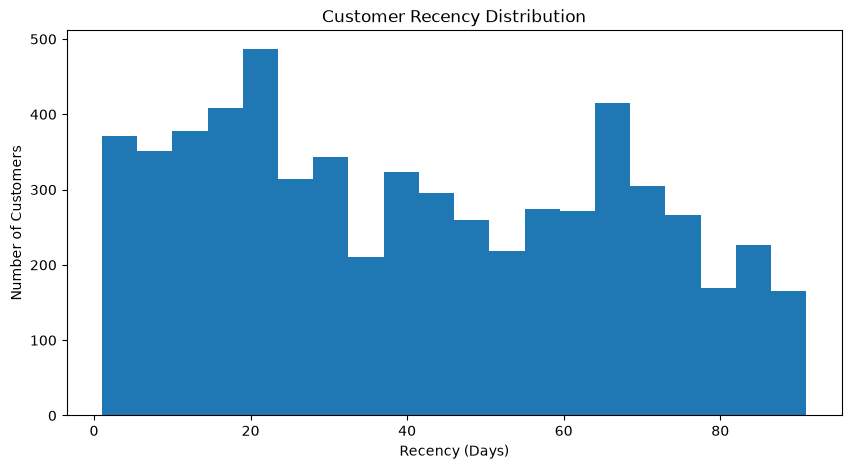

In [124]:
plt.figure(figsize=(10, 5))

plt.hist(rfm_df['recency'], bins=20)

plt.title('Customer Recency Distribution')
plt.xlabel('Recency (Days)')
plt.ylabel('Number of Customers')

plt.show()


**Recency Distribution — Observation**

Customer Recency ranges from 1 to 91 days, with a median of 39 days. The distribution shows noticeable concentrations around 15–22 days and 65–70 days, indicating variation in how recently customers made their last purchase.

Customers are spread across the observation period rather than concentrated within a single narrow time range. This variation makes Recency useful for distinguishing recently active customers from those who have not purchased for a longer period.



### 7.3 Frequency Distribution

Visualize the number of delivered orders placed by each customer.

The histogram helps identify the concentration of one-time buyers, repeat purchasers and high-frequency customers.

Because Frequency has a long right tail, a second zoomed view will focus on customers with up to 20 delivered orders while retaining the full distribution for context.


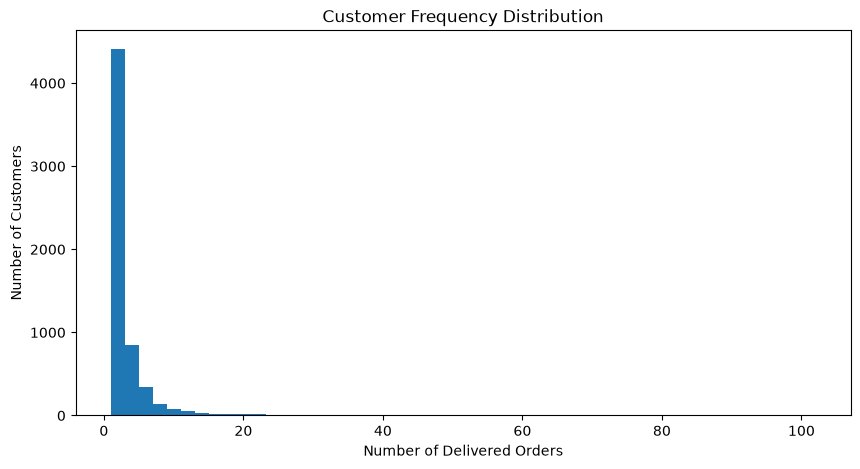

In [125]:
plt.figure(figsize=(10, 5))

plt.hist(rfm_df['frequency'], bins=50)

plt.title('Customer Frequency Distribution')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers')

plt.show()


### 7.3.1 Frequency Distribution — Zoomed View

The full Frequency distribution is dominated by customers with one or two delivered orders.

To examine the distribution among the majority of customers more clearly, create a zoomed histogram limited to customers with up to 20 delivered orders.

This is a visualization-only filter. All customers, including those with more than 20 orders, remain in the final RFM dataset.


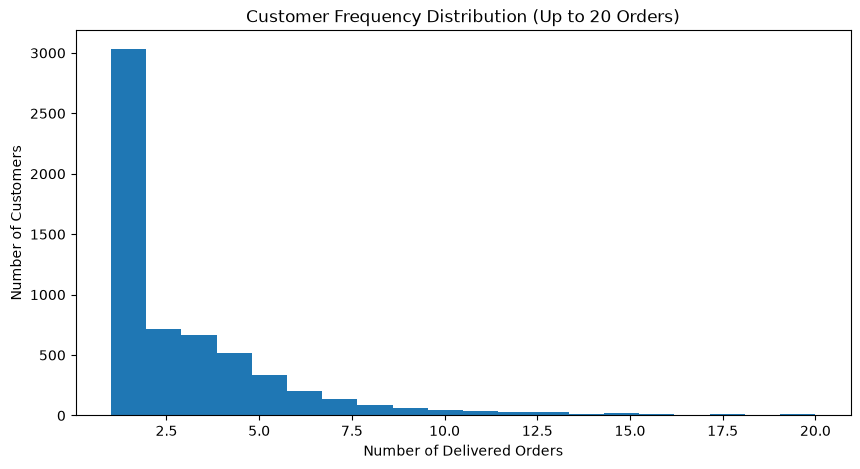

In [126]:
plt.figure(figsize=(10, 5))

plt.hist(
    rfm_df.loc[rfm_df['frequency'] <= 20, 'frequency'],
    bins=20
)

plt.title('Customer Frequency Distribution (Up to 20 Orders)')
plt.xlabel('Number of Delivered Orders')
plt.ylabel('Number of Customers')

plt.show()


**Frequency Distribution — Observation**

The Frequency distribution is strongly right-skewed. Approximately 50.13% of customers placed only one delivered order, and the median Frequency is one order, compared with a mean of 3.30.

The zoomed histogram shows a sharp decline in customer counts as order frequency increases. A relatively small group of customers makes frequent repeat purchases, with a few customers placing exceptionally high numbers of orders. The maximum Frequency is 102.

This indicates that the customer base contains a large proportion of one-time buyers alongside a smaller group of repeat and high-frequency customers.



### 7.4 Net Monetary Distribution

Visualize customer-level net spending after deducting successful refunds.

The linear-scale histogram shows the overall spending distribution and highlights the effect of high-spending customers.

A supplementary logarithmic-scale histogram with logarithmically spaced bins will help examine the distribution across a wider range of spending values.

Both plots use the final net Monetary feature from the RFM DataFrame.


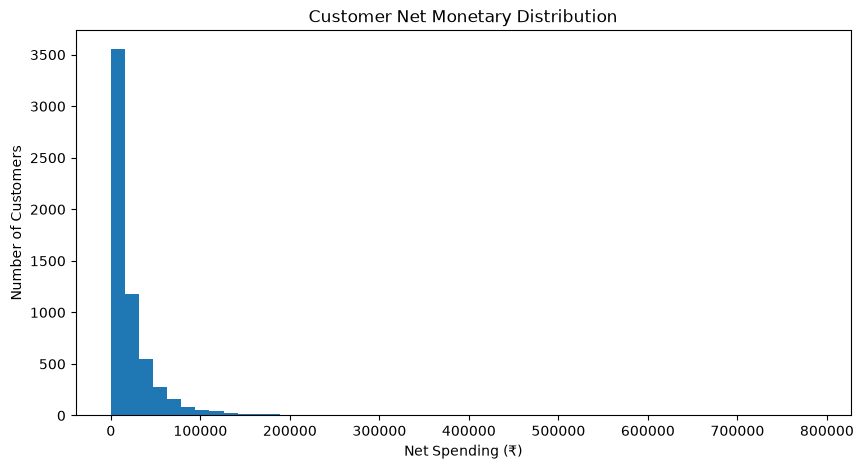

In [127]:
plt.figure(figsize=(10, 5))

plt.hist(rfm_df['monetary'], bins=50)

plt.title('Customer Net Monetary Distribution')
plt.xlabel('Net Spending (₹)')
plt.ylabel('Number of Customers')

plt.show()


### 7.4.1 Net Monetary Distribution — Log Scale

The linear-scale histogram shows the strong right skew in customer spending, with a small number of high-spending customers stretching the distribution.

A logarithmic-scale histogram with logarithmically spaced bins provides a clearer view across the wide range of net spending values.

This is a supplementary visualization. The underlying Monetary values remain unchanged.


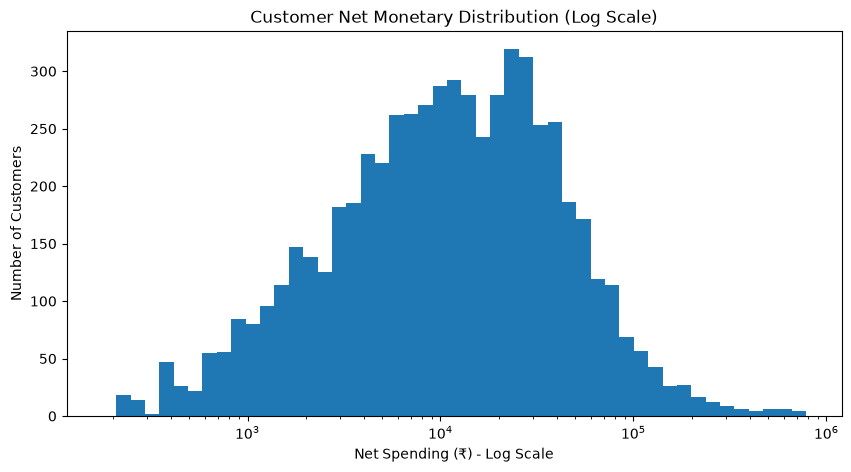

In [128]:
import numpy as np

net_monetary = rfm_df['monetary']

log_bins = np.logspace(
    np.log10(net_monetary[net_monetary > 0].min()),
    np.log10(net_monetary.max()),
    50
)

plt.figure(figsize=(10, 5))

plt.hist(
    net_monetary[net_monetary > 0],
    bins=log_bins
)

plt.xscale('log')

plt.title('Customer Net Monetary Distribution (Log Scale)')
plt.xlabel('Net Spending (₹) - Log Scale')
plt.ylabel('Number of Customers')

plt.show()


**Net Monetary Distribution — Observation**

The net Monetary distribution is strongly right-skewed. Most customers are concentrated in the lower and middle spending ranges, while a relatively small group accounts for substantially higher spending.

The logarithmic-scale histogram makes the distribution across spending ranges easier to examine. Despite deducting successful refunds, the distribution retains its long right tail, indicating considerable variation in customer spending.

Seventeen customers with zero net Monetary are excluded from this logarithmic visualization because zero cannot be represented on a logarithmic axis. They remain included in the final RFM dataset.



## 8. Net Spending vs Purchase Frequency

### 8.1 High-Value Customer Comparison

Investigate whether customers with the highest net spending generate more revenue through higher purchase frequency, higher average order value, or both.

Rank customers by net Monetary spending and divide them into the top 10% and remaining 90%.

Compare:
- Number of customers
- Average delivered orders per customer
- Average net spending per customer
- Average net order value
- Total net revenue contribution

This analysis helps understand the purchasing behaviour of high-value customers and supports future customer retention strategies.


In [129]:
# Rank customers by net Monetary spending
ranked_customers = rfm_df.sort_values(
    'monetary',
    ascending=False
).copy()

# Select the top 10% of customers
top_10_count = round(len(ranked_customers) * 0.10)

top_10 = ranked_customers.head(top_10_count)
remaining_90 = ranked_customers.iloc[top_10_count:]


### 8.2 Compare Customer Groups

Calculate customer counts, average purchase frequency, average net spending per customer, average net order value and total net revenue for both groups.

Average net order value is calculated as net Monetary divided by Frequency at the group level.


In [131]:
comparison = pd.DataFrame({
    'Top 10%': [
        len(top_10),
        top_10['frequency'].mean(),
        top_10['monetary'].mean(),
        top_10['monetary'].sum() / top_10['frequency'].sum(),
        top_10['monetary'].sum()
    ],
    'Remaining 90%': [
        len(remaining_90),
        remaining_90['frequency'].mean(),
        remaining_90['monetary'].mean(),
        remaining_90['monetary'].sum() / remaining_90['frequency'].sum(),
        remaining_90['monetary'].sum()
    ]
}, index=[
    'Customer Count',
    'Average Orders per Customer',
    'Average Net Spending per Customer',
    'Average Net Order Value',
    'Total Net Revenue'
])

comparison.style.format({
    'Top 10%': '{:,.2f}',
    'Remaining 90%': '{:,.2f}'
})

,Top 10%,Remaining 90%
Customer Count,605.00,"5,447.00"
Average Orders per Customer,13.09,2.21
Average Net Spending per Customer,"118,521.59","14,256.36"
Average Net Order Value,"9,054.88","6,439.00"
Total Net Revenue,"71,705,560.81","77,654,385.03"



### 8.3 Interpretation

The top 10% of customers generate approximately 48.0% of total net customer spending despite representing only 10% of the customer base.

Their average purchase frequency is approximately 5.92 times that of the remaining customers, while their average net order value is approximately 1.41 times higher.

This suggests that high-value customers generate greater spending through both more frequent purchases and higher average order values.

**Business implication:** Retention strategies for high-value customers are important for protecting revenue. Encouraging repeat purchases among the remaining customer base may also provide an opportunity to increase customer lifetime value.
